# neutral-model-methodology *(draft digest)*

> **Status:** DRAFT in `Research/_drafts/` — not yet approved into the `Research/` index.
> Entry into the index table is gated on user approval (see `Research/README.md` → *Drafting workflow*).

## Question

**Can excess-activity metrics separate *adaptive* evolution from mere drift / turnover?**

Raw cumulative-activity statistics (Bedau–Snyder–Packard 1998) count how much distinct
genetic material has *ever been present*. But under a high mutation rate — or under pure
turnover with no selection — raw activity stays high while *nothing adaptive is happening*.
The methods question this campaign answers is whether a correctly-constructed **neutral
shadow** can be subtracted off to isolate the adaptive component (the *excess*), and whether
that excess passes the sharp causal test: **it must be zero when the subsystem it measures is
frozen.**

## Method

Three ingredients, developed together:

1. **Fixed-space neutral shadows** (`eg-dyn-shadows`, merged commit `89ad3eb`). Two of EvoCA's
   activity channels live in *closed finite bucket spaces* — the egenome (`eg`, 729 ternary
   keys) and the used-transition channel (`dyn`, 500 LUT-entry buckets). For a fixed space the
   neutral baseline is a **Wright–Fisher multinomial-drift** occupancy driven by the run's
   *realised* mutation flux, with a closed-form variance — far cheaper and more rigorous than
   the open-ended LUT-hash shadow. Per-component excess = `ΣG/D_G − ΣN/D_N`.

2. **Reciprocal-freeze causal controls** (`Research/Activity-metrics/Scans/2026-05-16_causal_control`, then the
   bug-corrected `Research/Activity-metrics/Scans/2026-05-17_causal_control_v2`). Three arms at one fixed productive
   corner:
   - **JOINT** — LUT *and* egene both evolve (baseline);
   - **LUT_only** — egene frozen (`mu_egene = mu_egenome = 0`), LUT evolves;
   - **EGENE_only** — LUT frozen (`mu_lut = 0`), egene evolves.
   Because a *frozen* subsystem cannot evolve, its excess **must** read ≈ 0. This makes the
   control double as a **metric bug detector**.

3. **The two shadow-scope bugs those controls caught** (see the *Bug* section below).

**Model.** The controls and #3c first ran under the legacy uncapped mouthful (`food_cap=0`), which
is not part of the model. The main thread below reads the 2026-10-23 standard-model rescans
(`food_cap=1`; same drivers, arms, seeds and protocol, today's code). The controls run at
`m_scale = 1.2` and #3c at 3.0, so the rule can bind in every row. The recorded results are set
against the rescans in the final section, "Legacy rule (`food_cap=0`)".

## Headline result (standard model, 2026-10-23)

The fixed-space `eg`/`dyn` shadows **pass the null controls exactly** under both rules: the frozen
subsystem's excess is 0 (`eg_excess_pc_slope = 0` for LUT_only; `dyn_excess_pc_slope = 0` for
EGENE_only), while the evolving subsystem's excess stays strongly positive. The v1→v2 transition
closed a scope bug (whole-genome `excess_pc` is *undefined* for egene-driven runs: EGENE_only reads
-33 in v1 and -68 in v2). LUT and egene co-evolution still amplify each other, the `eg` channel by
less than recorded: JOINT/EGENE_only `eg` excess 63/45 = 1.4x (recorded 65/31 = 2.1x); JOINT/LUT_only
`dyn` excess 31/17 = 1.8x (unchanged).

**Changed:** the second scope bug that campaign #3c surfaced (`dyn_excess_pc` exploding on a frozen
rich substrate, arm A +335) **does not reproduce under the standard rule**: arm A reads -1.3, the
co-evolving arm C +3.6. The degenerate-baseline argument (zero realized LUT flux) still makes `dyn`
excess ill-posed for a frozen LUT, so the guard "interpret `dyn` only where `mu_lut > 0`" stays; the
recorded explosion is a legacy-rule result.

In [1]:
# --- draft digest notebook: shared setup ---
# Locates the repo root (dir containing C/evoca.h) by walking up from CWD,
# so the notebook loads raw artifacts wherever it is executed from.
from pathlib import Path
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

def repo_root():
    p = Path.cwd().resolve()
    for cand in [p, *p.parents]:
        if (cand / "C" / "evoca.h").is_file():
            return cand
    raise FileNotFoundError("could not locate repo root (no C/evoca.h above CWD)")

ROOT = repo_root()
print("repo root:", ROOT)


repo root: /private/tmp/evoca_food-cap-standard


### Reciprocal-freeze controls (v2, bug-corrected)

`causal_control_v2` standard-model rescan: 3 arms × 4 seeds, N=256, 15k ticks. The sharp prediction
is that a frozen subsystem's fixed-space excess reads exactly 0.

,excess_pc_slope,eg_excess_pc_slope,dyn_excess_pc_slope
arm,,,
JOINT,0.0002,63.2477,31.0841
LUT_only,0.0001,0.0000,17.1543
EGENE_only,-68.0364,45.0337,0.0000


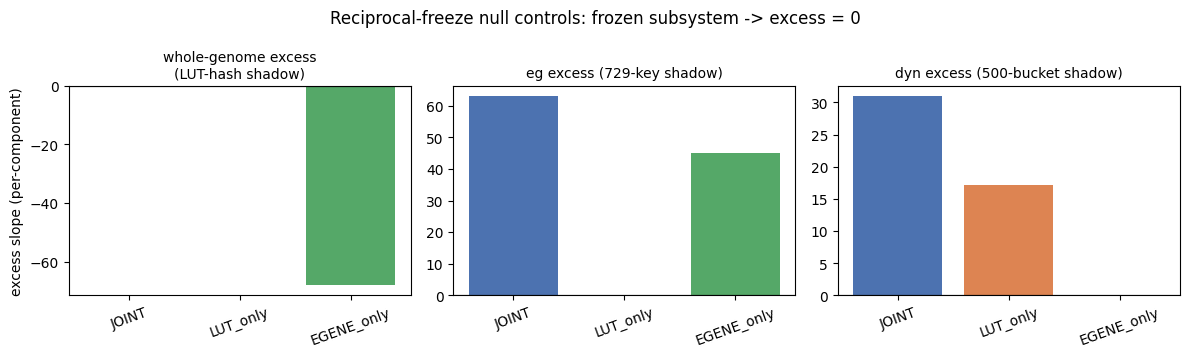

NULL CHECKS (should be ~0):
  LUT_only  eg_excess_pc_slope  = 0.0
  EGENE_only dyn_excess_pc_slope = 0.0


In [2]:
v2 = pd.read_csv(ROOT / "Research/Activity-metrics/Scans/2026-10-23_causal_control_v2_standard/results.csv")   # standard-model rescan
cols = ["excess_pc_slope", "eg_excess_pc_slope", "dyn_excess_pc_slope"]
summ = v2.groupby("arm")[cols].mean()
# order arms for readability
summ = summ.reindex(["JOINT", "LUT_only", "EGENE_only"])
display(summ.round(4))

fig, axes = plt.subplots(1, 3, figsize=(12, 3.6), sharex=True)
titles = {
    "excess_pc_slope": "whole-genome excess\n(LUT-hash shadow)",
    "eg_excess_pc_slope": "eg excess (729-key shadow)",
    "dyn_excess_pc_slope": "dyn excess (500-bucket shadow)",
}
arms = ["JOINT", "LUT_only", "EGENE_only"]
colors = ["#4C72B0", "#DD8452", "#55A868"]
for ax, col in zip(axes, cols):
    vals = [v2[v2.arm == a][col].mean() for a in arms]
    ax.bar(arms, vals, color=colors)
    ax.axhline(0, color="k", lw=0.8)
    ax.set_title(titles[col], fontsize=10)
    ax.tick_params(axis="x", rotation=20)
axes[0].set_ylabel("excess slope (per-component)")
fig.suptitle("Reciprocal-freeze null controls: frozen subsystem -> excess = 0", fontsize=12)
fig.tight_layout()
plt.show()

print("NULL CHECKS (should be ~0):")
print("  LUT_only  eg_excess_pc_slope  =", round(v2[v2.arm=="LUT_only"].eg_excess_pc_slope.mean(), 4))
print("  EGENE_only dyn_excess_pc_slope =", round(v2[v2.arm=="EGENE_only"].dyn_excess_pc_slope.mean(), 4))

### Bug 1 — LUT-only-mismatch (why v1 → v2 was necessary)

The Channon neutral shadow in `C/evoca.c` carries **LUT bytes only**, but `get_activity`
hashes the **full genome** (LUT ‖ sorted active egene bytes). So real diversity `D_G` includes
egene variation the shadow structurally cannot represent — and whole-genome
`excess_pc` is **meaningless for any egene-driven run**. The v1 EGENE_only arm exposes it: the
frozen-LUT / evolving-egene arm should have a *defined* signal, but whole-genome
`excess_pc_slope` reads ≈ −33 in the v1 rescan (consistent across seeds; recorded ≈ −26) — not "egene evolution fails," but the
metric being undefined. This is exactly why the fixed-space 729-key `eg` shadow was built.

In [3]:
v1 = pd.read_csv(ROOT / "Research/Activity-metrics/Scans/2026-10-23_causal_control_standard/results.csv")   # standard-model rescan
v1summ = v1.groupby("arm")[["excess_pc_slope", "excess_activity_slope"]].mean()
print("v1 (pre-fix) whole-genome excess by arm -- note the negative EGENE_only:")
display(v1summ.round(3))
print("v1 EGENE_only excess_pc_slope ~= %.1f  <-- undefined, NOT a real signal"
      % v1.query("arm=='EGENE_only'").excess_pc_slope.mean())

v1 (pre-fix) whole-genome excess by arm -- note the negative EGENE_only:


,excess_pc_slope,excess_activity_slope
arm,,
EGENE_only,-32.610,-11.320
JOINT,0.005,1.872
LUT_only,0.002,1.394


v1 EGENE_only excess_pc_slope ~= -32.6  <-- undefined, NOT a real signal


### Bug 2 — `dyn_excess_pc` frozen-rich-substrate artifact (caught by #3c; legacy rule only)

The `dyn` shadow is *realized-flux-driven*. When `mu_lut = 0` freezes a **rich, evolved**
substrate, the realized LUT flux → 0, so the neutral baseline has nothing to drift on while the
alive population keeps exercising the rich frozen rule. Under the legacy rule this made
`dyn_excess_pc` **explode** (#3c arm A ≈ +335 vs co-evolving arm C ≈ +1; final section). Under the
standard rule the same protocol gives arm A ≈ −1.3 and arm C ≈ +3.6 (below), on a substrate of the
same richness (`sub_n_lut` ≈ 36k vs 38k recorded), and frozen GoL (B) no longer goes extinct. So the
explosion is not a property of the shadow alone; it needed the legacy dynamics (arm A's population
grew to ~49k of 65k cells under the legacy rule, ~29k under the standard rule). The v2 `dyn`-null
froze **GoL** (a *sparse* substrate) and says nothing about a frozen evolved substrate either way.
Rule kept as a guard: do not interpret `dyn_excess_pc` for an arm whose LUT is frozen on a
non-trivial evolved substrate; a direct test at `m_scale <= 1` (where both rules agree) is open
(Activity-metrics ACT-Q10).

In [4]:
c3 = pd.read_csv(ROOT / "Research/Lineage-co-evolution/Scans/2026-10-23_3c_coevolution_substrate_standard/results.csv")   # standard-model rescan
byarm = c3.groupby("arm").agg(
    n=("arm", "size"),
    extinct=("extinct", "sum"),
    sub_n_lut=("sub_n_lut", "mean"),
    final_pop=("final_pop", "mean"),
    dyn_excess_pc_slope=("dyn_excess_pc_slope", "mean"),
    eg_excess_pc_slope=("eg_excess_pc_slope", "mean"),
).round(2)
display(byarm)
print("arm A (mu_lut=0 on EVOLVED substrate) dyn_excess_pc_slope ~= %.2f"
      % c3.query("arm=='A'").dyn_excess_pc_slope.mean())
print("arm C (LUT co-evolving) dyn_excess_pc_slope ~= %.2f"
      % c3.query("arm=='C'").dyn_excess_pc_slope.mean())

,n,extinct,sub_n_lut,final_pop,dyn_excess_pc_slope,eg_excess_pc_slope
arm,,,,,,
A,30,0,35912.17,28949.73,-1.33,-1.63
B,10,0,1.00,18314.40,0.00,0.69
B',10,0,1.00,9960.70,0.00,1.44
C,30,0,35912.17,13822.13,3.56,-1.19


arm A (mu_lut=0 on EVOLVED substrate) dyn_excess_pc_slope ~= -1.33
arm C (LUT co-evolving) dyn_excess_pc_slope ~= 3.56


### Takeaways

- **The fixed-space `eg`/`dyn` shadows are the trustworthy instrument**: closed-form drift
  baselines, and they pass the reciprocal-freeze nulls exactly under both eating rules.
- **The whole-genome LUT-hash `excess_pc` is scope-limited**: undefined whenever egenes evolve
  (Bug 1) and turnover-fragile at high `mu_lut` (the original `neutral_apply_demography`
  no-heredity flaw, `Docs/EvoCA_research_directions.md` §2).
- **`dyn_excess_pc` on frozen evolved substrates**: exploded under the legacy rule (Bug 2), not
  under the standard rule. Keep it out of LUT-frozen arms as a guard until tested directly; use the
  `eg`-shadow + lineage net-return there.
- **Co-evolution synergy**: `dyn` 1.8x and `eg` 1.4x (JOINT over the single-subsystem arm) under the
  standard rule; the `eg` figure was 2.1x under the legacy rule.

*Sources:* `Docs/EvoCA_research_directions.md` §2; `Research/Activity-metrics/Scans/2026-10-23_causal_control_standard/`,
`Research/Activity-metrics/Scans/2026-10-23_causal_control_v2_standard/`; `Research/Lineage-co-evolution/Scans/2026-10-23_3c_coevolution_substrate_standard/`
(standard-model rescans of `2026-05-16_causal_control`, `2026-05-17_causal_control_v2`, `2026-05-19_3c_coevolution_substrate`); project
memories `shadow-models-lut-only-mismatch`, `dyn-shadow-frozen-rich-substrate`.

## Legacy rule (`food_cap=0`): results that depend on it

The recorded runs used the legacy uncapped mouthful, under which `m_scale x score > 25` overdraws the
site, drives `F` negative and drains the next eater's private food (defect A9). It is not part of the
model. Recorded against rescan, for the two findings that moved: the v2 `eg` synergy and the #3c arm-A
`dyn` explosion. Nothing above depends on this section.

In [5]:
A = ROOT / "Research/Activity-metrics/Scans"
k = ["excess_pc_slope", "eg_excess_pc_slope", "dyn_excess_pc_slope", "final_pop"]
v2_rec = pd.read_csv(A / "2026-05-17_causal_control_v2/results.csv")
print("causal_control_v2, mean by arm (m_scale 1.2):")
display(pd.concat({"recorded": v2_rec.groupby("arm")[k].mean(), "rescan": v2.groupby("arm")[k].mean()}, axis=1)
          .reindex(["JOINT", "LUT_only", "EGENE_only"]).round(2))
c3_rec = pd.read_csv(ROOT / "Research/Lineage-co-evolution/Scans/2026-05-19_3c_coevolution_substrate/results.csv")
agg = dict(extinct=("extinct", "sum"), sub_n_lut=("sub_n_lut", "mean"), final_pop=("final_pop", "mean"),
           dyn_excess_pc_slope=("dyn_excess_pc_slope", "mean"), eg_excess_pc_slope=("eg_excess_pc_slope", "mean"))
print("#3c, mean by arm (m_scale 3.0):")
display(pd.concat({"recorded": c3_rec.groupby("arm").agg(**agg), "rescan": c3.groupby("arm").agg(**agg)}, axis=1).round(2))

causal_control_v2, mean by arm (m_scale 1.2):


recorded                                                   \
           excess_pc_slope eg_excess_pc_slope dyn_excess_pc_slope final_pop   
arm                                                                           
JOINT                 0.00              64.79               32.95  19241.50   
LUT_only              0.00               0.00               17.29  10609.75   
EGENE_only          -46.44              30.96                0.00  13064.25   

                    rescan                                                   
           excess_pc_slope eg_excess_pc_slope dyn_excess_pc_slope final_pop  
arm                                                                          
JOINT                 0.00              63.25               31.08  18986.75  
LUT_only              0.00               0.00               17.15  10495.00  
EGENE_only          -68.04              45.03                0.00  17382.75

#3c, mean by arm (m_scale 3.0):


recorded                                                             \
     extinct sub_n_lut final_pop dyn_excess_pc_slope eg_excess_pc_slope   
arm                                                                       
A          0  37995.93  48949.30              335.33              -0.38   
B         10      0.00      0.00                0.00               0.00   
B'         0      1.00  55639.00                0.00              -0.00   
C          0  37995.93  27093.27                1.01               0.24   

     rescan                                                             
    extinct sub_n_lut final_pop dyn_excess_pc_slope eg_excess_pc_slope  
arm                                                                     
A         0  35912.17  28949.73               -1.33              -1.63  
B         0      1.00  18314.40                0.00               0.69  
B'        0      1.00   9960.70                0.00               1.44  
C         0  35912.17  13822.13                3.56              -1.19